<a href="https://colab.research.google.com/github/Alishfa/python-data-analysis/blob/main/online-store-data-analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 22.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 37.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:
import streamlit as st
from google.colab import files
from pathlib import Path
import shutil

Path("data").mkdir(exist_ok=True)
Path("output").mkdir

uploaded = files.upload()
source_name = next(iter(uploaded))
shutil.move(source_name,"data/orders_raw.csv")

print("Raw data saved to : data/orders_raw.csv")

Saving orders_raw.csv to orders_raw.csv
Raw data saved to : data/orders_raw.csv


In [ ]:
Path("data2").mkdir(exist_ok=True)
upload = files.upload()
print(upload)
source_name = next(iter(upload))
print(source_name)
shutil.move(source_name, "data2/orders_raw.csv")

print("Raw data saved to : data2/orders_raw.csv")

Saving orders_raw.csv to orders_raw (1).csv
{'orders_raw (1).csv': b'order_id,order_date,region,category,quantity,unit_price,order_value,delivery_days,status\n10001,2025-05-14,West,Home,4.0,90.0,360.0,8.0,Delivered\n10002,2025-02-14,East,Electronics,1.0,120.0,120.0,1.0,Delivered\n10003,2025-04-09,West,Home,3.0,90.0,270.0,1.0,Cancelled\n10004,2025-02-05,North,Fashion,5.0,25.0,125.0,2.0,Delivered\n10005,2025-05-17,South,Home,2.0,30.0,60.0,5.0,\n10006,2025-03-21,West,Electronics,5.0,650.0,3250.0,3.0,Returned\n10007,2025-02-06,West,home,3.0,30.0,-90.0,5.0,Cancelled\n10008,2025-04-06,North,Home,1.0,30.0,30.0,6.0,Cancelled\n10009,2025-04-06,North,Beauty,5.0,15.0,75.0,,Delivered\n10010,2025-05-23,south ,Fashion,3.0,40.0,120.0,4.0,Delivered\n10011,2025-03-10,North,Home,3.0,55.0,165.0,8.0,Returned\n10012,2025-05-23,South,Home,5.0,90.0,450.0,6.0,Delivered\n10013,2025-03-23,South,Home,2.0,30.0,60.0,4.0,Returned\n10014,2025-05-29,East,Home,2.0,30.0,60.0,4.0,Delivered\n10015,2025-03-31,north ,Beaut

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/orders_raw.csv")

# Using display() to output multiple tables in a single cell
print("--- DF HEAD ---")
display(df.head())

print("\n--- DF INFO ---")
df.info()

print("\n--- DF DESCRIBE ---")
display(df.describe())

--- DF HEAD ---


,order_id,order_date,region,category,quantity,unit_price,order_value,delivery_days,status
0,10001,2025-05-14,West,Home,4.0,90.0,360.0,8.0,Delivered
1,10002,2025-02-14,East,Electronics,1.0,120.0,120.0,1.0,Delivered
2,10003,2025-04-09,West,Home,3.0,90.0,270.0,1.0,Cancelled
3,10004,2025-02-05,North,Fashion,5.0,25.0,125.0,2.0,Delivered
4,10005,2025-05-17,South,Home,2.0,30.0,60.0,5.0,NaN



--- DF INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 223 entries, 0 to 222
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       223 non-null    int64  
 1   order_date     223 non-null    object 
 2   region         223 non-null    object 
 3   category       223 non-null    object 
 4   quantity       218 non-null    float64
 5   unit_price     223 non-null    object 
 6   order_value    223 non-null    float64
 7   delivery_days  216 non-null    float64
 8   status         220 non-null    object 
dtypes: float64(3), int64(1), object(5)
memory usage: 15.8+ KB

--- DF DESCRIBE ---


,order_id,quantity,order_value,delivery_days
count,223.000000,218.000000,223.000000,216.000000
mean,10109.318386,3.059633,331.515695,4.884259
std,64.055170,1.384950,581.210261,2.424781
min,10001.000000,1.000000,-700.000000,1.000000
25%,10053.500000,2.000000,60.000000,3.000000
50%,10109.000000,3.000000,120.000000,5.000000
75%,10164.500000,4.000000,280.000000,7.000000
max,10220.000000,5.000000,3250.000000,9.000000


In [ ]:
missing_val = df.isna().sum()
print(f"missing vaues are : {missing_val}")
dup_val=df.duplicated().sum()
print(f"duplicate values are : {dup_val}")
print(df.shape[0])

missing vaues are : order_id         0
order_date       0
region           0
category         0
quantity         5
unit_price       0
order_value      0
delivery_days    7
status           3
dtype: int64
duplicate values are : 3
223


# **data cleaning'**

In [ ]:
def clean_data(file_path):
  # Load the DataFrame
  df = pd.read_csv(file_path)
  clean = df.copy()

  # 1. Standardize text columns
  for col in ['region', 'category', 'status']:
    clean[col] = clean[col].astype("string").str.strip().str.title()
    print(f"Cleaned {col}")

  # 2. Convert date column
  clean["order_date"] = pd.to_datetime(clean["order_date"], errors="coerce")

  # 3. Convert numeric columns
  numeric_cols = ["quantity",  "delivery_days","unit_price" , "order_value"]
  for col in numeric_cols:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")

  # 4. Remove exact duplicate values
  clean = clean.drop_duplicates()
  print("Removed duplicate rows")

  # 5. Handle missing values
  # Drop rows where 'status' is missing as it is a critical label
  clean = clean.dropna(subset=['status'])
  print("Dropped rows where 'status' was missing")

  # Impute missing 'quantity' with the median value
  median_quantity = clean['quantity'].median()
  clean['quantity'] = clean['quantity'].fillna(median_quantity)
  print(f"Imputed missing 'quantity' with median: {median_quantity}")

  # Impute missing 'delivery_days' with the median value
  median_delivery = clean['delivery_days'].median()
  clean['delivery_days'] = clean['delivery_days'].fillna(median_delivery)
  print(f"Imputed missing 'delivery_days' with median: {median_delivery}")
  median_price = clean['unit_price'].median()
  clean['unit_price'] = clean['unit_price'].fillna(median_price)
  print(f"Imputed missing 'unit_price' with median: {median_price}")

  return clean

# Call the function and save the cleaned data to a new variable
df_cleaned = clean_data("data/orders_raw.csv")
display(df_cleaned.head(50))
display( df_cleaned.isna().sum())
display(df_cleaned.shape[0])

Cleaned region
Cleaned category
Cleaned status
Removed duplicate rows
Dropped rows where 'status' was missing
Imputed missing 'quantity' with median: 3.0
Imputed missing 'delivery_days' with median: 5.0
Imputed missing 'unit_price' with median: 55.0


,order_id,order_date,region,category,quantity,unit_price,order_value,delivery_days,status
0,10001,2025-05-14,West,Home,4.0,90.0,360.0,8.0,Delivered
1,10002,2025-02-14,East,Electronics,1.0,120.0,120.0,1.0,Delivered
2,10003,2025-04-09,West,Home,3.0,90.0,270.0,1.0,Cancelled
3,10004,2025-02-05,North,Fashion,5.0,25.0,125.0,2.0,Delivered
5,10006,2025-03-21,West,Electronics,5.0,650.0,3250.0,3.0,Returned
6,10007,2025-02-06,West,Home,3.0,30.0,-90.0,5.0,Cancelled
7,10008,2025-04-06,North,Home,1.0,30.0,30.0,6.0,Cancelled
8,10009,2025-04-06,North,Beauty,5.0,15.0,75.0,5.0,Delivered
9,10010,2025-05-23,South,Fashion,3.0,40.0,120.0,4.0,Delivered
10,10011,2025-03-10,North,Home,3.0,55.0,165.0,8.0,Returned


,0
order_id,0
order_date,8
region,0
category,0
quantity,0
unit_price,0
order_value,0
delivery_days,0
status,0


218

In [ ]:
def quality_report(raw_file , df_cleaned):
  report = pd.DataFrame({
     'attributes' : ["rows before cleaning" , "rows after cleaning","removed rows"],
      'entries' : [
          len(pd.read_csv(raw_file)),
          len(df_cleaned),
          len(pd.read_csv(raw_file)) - len(df_cleaned)
      ]
  })
  # Save the report as a CSV file
  report.to_csv('report.csv', index=False)
  return report

report = quality_report("data/orders_raw.csv", df_cleaned)
display(report)

files.download('report.csv')

,attributes,entries
0,rows before cleaning,223
1,rows after cleaning,218
2,removed rows,5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df.head(30)

,order_id,order_date,region,category,quantity,unit_price,order_value,delivery_days,status
0,10001,2025-05-14,West,Home,4.0,90.0,360.0,8.0,Delivered
1,10002,2025-02-14,East,Electronics,1.0,120.0,120.0,1.0,Delivered
2,10003,2025-04-09,West,Home,3.0,90.0,270.0,1.0,Cancelled
3,10004,2025-02-05,North,Fashion,5.0,25.0,125.0,2.0,Delivered
4,10005,2025-05-17,South,Home,2.0,30.0,60.0,5.0,NaN
5,10006,2025-03-21,West,Electronics,5.0,650.0,3250.0,3.0,Returned
6,10007,2025-02-06,West,home,3.0,30.0,-90.0,5.0,Cancelled
7,10008,2025-04-06,North,Home,1.0,30.0,30.0,6.0,Cancelled
8,10009,2025-04-06,North,Beauty,5.0,15.0,75.0,NaN,Delivered
9,10010,2025-05-23,south,Fashion,3.0,40.0,120.0,4.0,Delivered


In [ ]:
print("----region count----")
region_count = df_cleaned.value_counts(['region']).to_frame().reset_index()
print(region_count)
for i in region_count:
  c = region_count ['count'].sum()
print(c)
print("----total sales----")
total_sales = df_cleaned['order_value'].sum()
print(total_sales)
print("----total quantity----")
total_quantity = df_cleaned['quantity'].sum()
print(total_quantity)
print("----total delivery days----")
total_delivery_days = df_cleaned['delivery_days'].sum()
print(total_delivery_days)
print("---region summary----")
region_summary = df_cleaned.groupby('region')["order_value"].agg(['sum','count'])
print(region_summary)
print("order by category")
category_count = df_cleaned.value_counts(['category']).to_frame().reset_index()
print(category_count)
print("order by status")
status_count = df_cleaned.value_counts(['status']).to_frame().reset_index()
print(status_count)
print("----category summary----")
category_summary = df_cleaned.groupby('category')["order_value"].agg(['sum','count'])
print(category_summary)
category_by_region = df_cleaned.groupby(['region','category'])["order_value"].agg(['sum','count'])
print(category_by_region)
display(pd.crosstab(df_cleaned['region'], df_cleaned['category']))
#

----region count----
  region  count
0   West     57
1   East     55
2  North     53
3  South     53
218
----total sales----
72998.0
----total quantity----
668.0
----total delivery days----
1055.0
---region summary----
            sum  count
region                
East     8637.0     55
North   20517.0     53
South   17950.0     53
West    25894.0     57
order by category
      category  count
0         Home     59
1       Beauty     55
2      Fashion     53
3  Electronics     51
order by status
      status  count
0  Delivered    136
1   Returned     45
2  Cancelled     37
----category summary----
                 sum  count
category                   
Beauty        3323.0     55
Electronics  53730.0     51
Fashion       4375.0     53
Home         11570.0     59
                        sum  count
region category                   
East   Beauty        1407.0     23
       Electronics   3640.0      6
       Fashion       1010.0     15
       Home          2580.0     11
North  Beauty   

category,Beauty,Electronics,Fashion,Home
region,,,,
East,23,6,15,11
North,10,19,8,16
South,12,13,15,13
West,10,13,15,19


## histogram

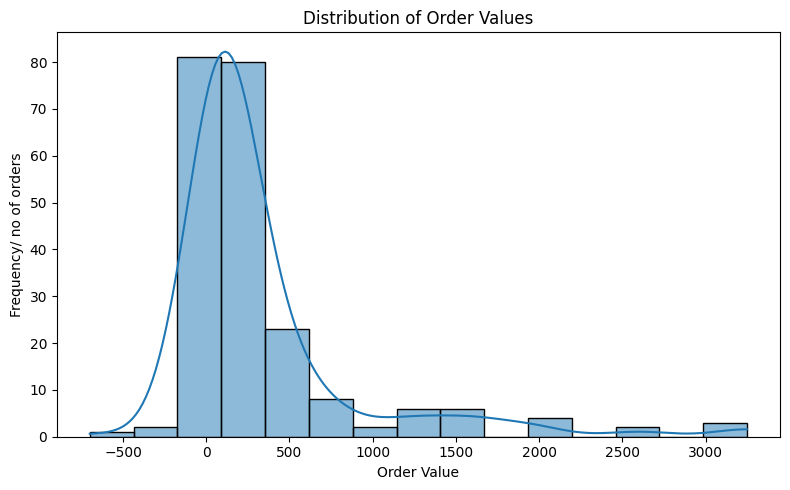

In [115]:
plt.figure(figsize=(8,5))
sns.histplot(data=df_cleaned, x="order_value", bins =15, kde=True)
plt.title("Distribution of Order Values")
plt.xlabel("Order Value")
plt.ylabel("Frequency/ no of orders")
plt.tight_layout()

plt.show()

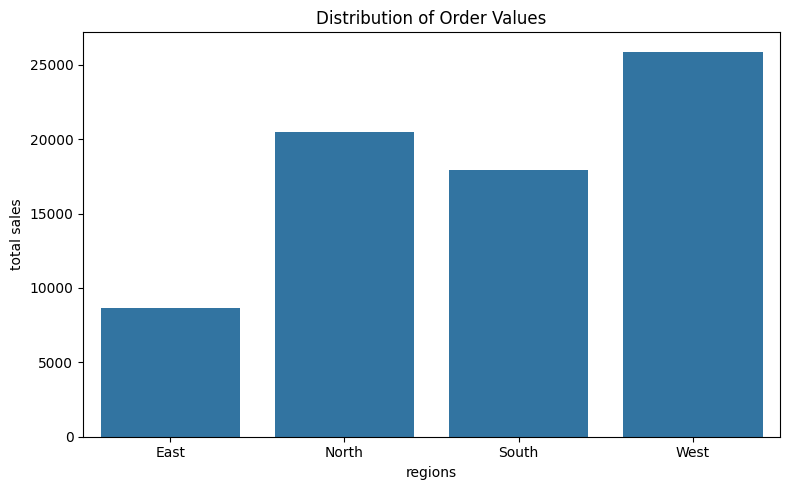

In [116]:
total_sales= df_cleaned.groupby('region')['order_value'].sum().reset_index()
plt.figure(figsize=(8,5))
sns.barplot(data=total_sales, x="region",y = "order_value" )
plt.title("Distribution of Order Values")
plt.xlabel("regions")
plt.ylabel("total sales")
plt.tight_layout()

plt.show()

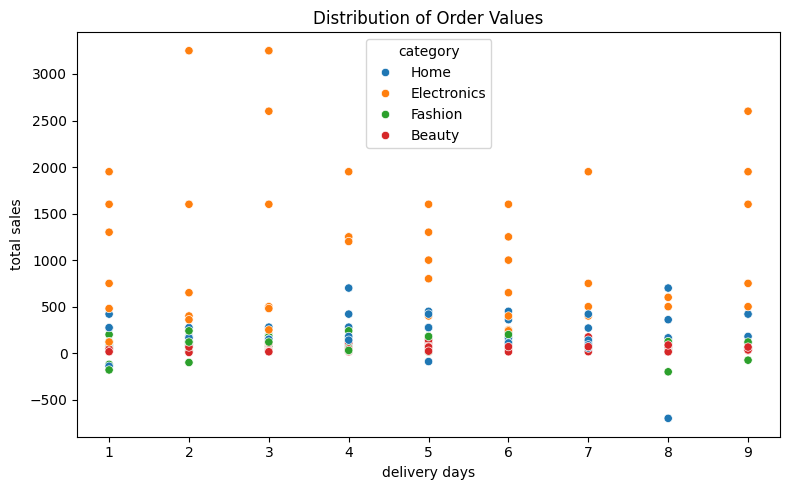

In [117]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df_cleaned , x="delivery_days",
                y="order_value",
                hue="category"
                )
plt.title("Distribution of Order Values")
plt.xlabel("delivery days")
plt.ylabel("total sales")
plt.tight_layout()

plt.show()


In [118]:
import plotly.express as px
fig = px.bar(
    total_sales,
    x="region",
    y="order_value",
    title="Total Sales by Region",
    labels={"region": "Region", "order_value": "Total Sales"},
)
fig.show()

In [119]:
import ipywidgets as widgets
from IPython.display import display , clear_output


In [120]:
from pandas._config import options
region_options = ["All"] + sorted(df_cleaned["region"].dropna().unique().tolist())
print(region_options)
category_options = ["All"] + sorted(df_cleaned["category"].dropna().unique().tolist())
print(category_options)
region_filter = widgets.Dropdown(
    options=region_options,
    value="All",
    description="Region:",
)
category_filter = widgets.Dropdown(
    options=category_options,
    value="All",
    description="Category:"
)
output_area = widgets.Output()
def update_notebook_dashboard(change = None):
  with output_area:
    clear_output(wait=True)
    filtered_df = df_cleaned.copy()
    if region_filter.value != "All":
      filtered_df = filtered_df[filtered_df["region"] == region_filter.value]
    if category_filter.value != "All":
      filtered_df = filtered_df[filtered_df["category"] == category_filter.value]
    display(filtered_df)
    print("orders:", len(filtered_df))
    print("total Sales:", round(filtered_df["order_value"].sum(),2))
    display(filtered_df.head(10))

    if not filtered_df.empty:
      summary= filtered_df.groupby("region")["order_value"].sum()
      fig = px.bar(
          summary,
          x="region",
          y="order_value",
          title="Total Sales by Region",
          labels={"region": "Region", "order_value": "Total Sales"},
      )
      fig.show()

region_filter.observe(update_notebook_dashboard, names="value")
category_filter.observe(update_notebook_dashboard, names="value")
display(widgets.HBox([region_filter, category_filter]))
display(output_area)
update_notebook_dashboard()
#

['All', 'East', 'North', 'South', 'West']
['All', 'Beauty', 'Electronics', 'Fashion', 'Home']


Output()

In [121]:
from google.colab import userdata
key =userdata.get('ngrok_key')

In [122]:
!pip install pyngrok
from pyngrok import ngrok
ngrok.set_auth_token(key)


PyngrokNgrokError: An error occurred when saving the auth token: b'Authtoken already set in configuration file: /root/.config/ngrok/ngrok.yml\n'

In [ ]:
app_code = r"""
import streamlit as st
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px


st.set_page_config(page_title = "order insight dashboard" , page_icon = "📊", layout = "wide")
st.title("online store -order insights")
df = pd.read_csv("orders_raw.csv")
parse_date = ["order_date"]

regions = sorted(df["region"].dropna().unique())
categories = sorted(df["category"].dropna().unique())

selected_region =st.multiselect("select a region", regions , default = regions)
selected_category =st.multiselect("select a category", categories , default = categories)

filtered = df [
  df['region'].isin(selected_region) &
  df['category'].isin(selected_category)
]
c1, c2, c3 = st.columns(3)
c1.metric("Total Orders", len(filtered))
c2.metric("Total Sales", round(filtered["order_value"].sum(), 2))
c3.metric("Average Order Value", round(filtered["order_value"].mean(), 2) if len(filtered) else "0")
sales = filtered.groupby("region", as_index=False)["order_value"].sum()
st.plotly_chart(px.bar(sales, x="region", y = "order_value", title = "Total Sales by Region"), use_container_width=True)

st.dataframe(filtered,use_container_width=True)

st.download_button(
  "Download Filtered Data",
  filtered.to_csv(index=False).encode("utf-8"),
  "filetered_orders.csv"
  "text/csv"
)


"""
with open ("app.py","w",encoding="utf-8") as f:
  f.write(app_code)
  print("app.py created successfully")

In [ ]:
import time
ngrok.kill()

!nohup streamlit run app.py --server.port 8501 > streamlit.log 2>&1 &
time.sleep(5)
public_url = ngrok.connect(8501)
print("Public URL:", public_url)